In [1]:

# 1. Install gdown
!pip -q install gdown

# 2. Download your Google Drive ZIP file
import gdown
import os

file_id = "1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM"
zip_path = "/kaggle/working/dataset.zip"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, zip_path, quiet=False)

# 3. Verify the download
if os.path.exists(zip_path):
    print(f"Download complete: {zip_path}")
    print(f"File size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")
else:
    print("Download failed. Check the Drive sharing permissions.")


Downloading...
From (original): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM
From (redirected): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM&confirm=t&uuid=f33e8f3d-53e9-4b48-961c-4b17c8daaff1
To: /kaggle/working/dataset.zip
100%|██████████| 804M/804M [00:15<00:00, 50.4MB/s] 

Download complete: /kaggle/working/dataset.zip
File size: 0.75 GB


In [2]:

import zipfile
import os

zip_path = "/kaggle/working/dataset.zip"
extract_path = "/kaggle/working/dataset"

if os.path.isfile(zip_path) and zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)
    print("Extracted to:", extract_path)
    print("Files:", os.listdir(extract_path)[:20])
else:
    print("ZIP file is missing, incomplete, or invalid.")


Extracted to: /kaggle/working/dataset
Files: ['noise_project_v2']


In [3]:

import os

folder = "/kaggle/working/dataset/noise_project_v2"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = "    " * (level + 1)
    for file in files[:20]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs.clear()


noise_project_v2/
    clean_list.csv
    noisy_metadata_v2.csv
    noise_manifest_v2.json
    b6000_split.csv
    clean_500/
        S/
            00002578_S_500_slap_05.png
            00002523_S_500_slap_01.png
            00002583_S_500_slap_08.png
            00002615_S_500_slap_08.png
            00002584_S_500_slap_02.png
            00002581_S_500_slap_06.png
            00002493_S_500_slap_04.png
            00002591_S_500_slap_02.png
            00002630_S_500_slap_08.png
            00002480_S_500_slap_07.png
            00002518_S_500_slap_07.png
            00002588_S_500_slap_04.png
            00002640_S_500_slap_06.png
            00002579_S_500_slap_01.png
            00002433_S_500_slap_05.png
            00002528_S_500_slap_04.png
            00002586_S_500_slap_04.png
            00002646_S_500_slap_08.png
            00002504_S_500_slap_09.png
            00002538_S_500_slap_01.png
        R/
            00002379_R_500_slap_07.png
            00002379_R_500_slap_01

In [4]:
!pip install -q "nbis-python>=0.1.17" scikit-image
import os, time, random
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch
import torch.nn as nn, torch.nn.functional as F
from numpy.lib.stride_tricks import sliding_window_view
from skimage.metrics import structural_similarity as ssim_fn
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ROOT = Path("/kaggle/working/dataset/noise_project_v2")
CLEAN_DIR, NOISY_DIR = ROOT/"clean_500", ROOT/"noisy_500_v2"
OUT = Path("/kaggle/working/denseunet_302b")
for d in ["ckpt", "enhanced_test", "visuals"]: (OUT/d).mkdir(parents=True, exist_ok=True)

SEED = 42
PS, STEP = 60, 20                      # paper: 60x60 patch, 20x20 scan step
BS, ITERS, EPOCHS, LR = 128, 300, 40, 1e-3
N_ITER = 1                             # paper scans iteratively; 1 = single scan (ablation neeche)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda")
print(torch.__version__, torch.cuda.get_device_name(0))

2.11.0+cu128 Tesla T4


In [5]:
rows = []
for p in sorted(CLEAN_DIR.rglob("*.png")):
    rel = p.relative_to(CLEAN_DIR); n = NOISY_DIR/rel
    if n.exists():
        rows.append(dict(rel=str(rel), stem=p.stem, ftype=rel.parts[0],
                         participant=int(p.stem.split("_")[0]), clean=str(p), noisy=str(n)))
pairs = pd.DataFrame(rows); print("pairs found:", len(pairs))

sp = pd.read_csv(ROOT/"b6000_split.csv"); sp.columns = [c.strip().lower() for c in sp.columns]
sp["split"] = (sp["split"].astype(str).str.strip().str.lower()
               .replace({"validation": "val", "valid": "val", "training": "train"}))
if "key" in sp.columns and sp["key"].astype(str).isin(pairs.stem).mean() > 0.9:
    pairs["split"] = pairs.stem.map(dict(zip(sp["key"].astype(str), sp["split"]))); print("split by key")
else:
    sp["participant"] = pd.to_numeric(sp["participant"], errors="coerce")
    sp = sp.dropna(subset=["participant"]); sp["participant"] = sp["participant"].astype(int)
    pairs["split"] = pairs.participant.map(sp.drop_duplicates("participant").set_index("participant")["split"])
    print("split by participant")
pairs = pairs.dropna(subset=["split"])
assert pairs.groupby("participant")["split"].nunique().max() == 1
train_df, val_df, test_df = [pairs[pairs.split == s].reset_index(drop=True) for s in ["train", "val", "test"]]
print("train/val/test:", len(train_df), len(val_df), len(test_df))   # expected 1764/388/338

pairs found: 2490
split by participant
train/val/test: 1764 388 338


In [6]:
def load_gray(paths): return [cv2.imread(p, 0) for p in paths]
tr_n, tr_c = load_gray(train_df.noisy), load_gray(train_df.clean)
va_n, va_c = load_gray(val_df.noisy),   load_gray(val_df.clean)
assert min(min(a.shape) for a in tr_n + va_n) >= PS
print("cache: %.2f GB" % (sum(a.nbytes for a in tr_n + tr_c + va_n + va_c) / 1e9))

def sample_patch(N, C, rng, aug):
    for _ in range(10):                          # paper: low-variance patches hata do
        k = rng.randint(len(N)); n, c = N[k], C[k]
        y = rng.randint(n.shape[0] - PS + 1); x = rng.randint(n.shape[1] - PS + 1)
        pn, pc = n[y:y+PS, x:x+PS], c[y:y+PS, x:x+PS]
        if pc.std() > 8 or rng.rand() < 0.1: break   # 10% blank patches rakhe, taaki background bhi seekhe
    if aug:
        if rng.rand() < .5: pn, pc = pn[:, ::-1], pc[:, ::-1]
        k = rng.randint(4); pn, pc = np.rot90(pn, k), np.rot90(pc, k)
    return pn, pc

def get_batch(N, C, bs, rng, aug=True):
    ps = [sample_patch(N, C, rng, aug) for _ in range(bs)]
    f = lambda i: torch.from_numpy(np.ascontiguousarray(np.stack([p[i] for p in ps]))).float().div(255).unsqueeze(1)
    return f(0), f(1)

rng_tr = np.random.RandomState(SEED)
rv = np.random.RandomState(0)                    # fixed validation patches (20 per val image)
VX, VY = get_batch(va_n, va_c, 20 * len(va_n), rv, aug=False)
print(VX.shape)

cache: 1.68 GB
torch.Size([7760, 1, 60, 60])


In [7]:
class ConvS(nn.Module):                  # stride-1 conv, 'same' padding (4x4 bhi chalega) + ReLU
    def __init__(s, cin, cout, k, act=True):
        super().__init__(); t = k - 1; l = t // 2
        s.pad = nn.ZeroPad2d((l, t - l, l, t - l)); s.conv = nn.Conv2d(cin, cout, k); s.act = act
    def forward(s, x):
        x = s.conv(s.pad(x)); return F.relu(x) if s.act else x

class DenseBlock(nn.Module):             # 6 conv layers 3x3; har layer ko pichhle sabke outputs milte hain
    def __init__(s, cin, c=32, g=16, L=6):
        super().__init__()
        s.layers = nn.ModuleList([ConvS(cin + i * g, g, 3) for i in range(L)])
        s.comp = nn.Conv2d(L * g, c, 1)
    def forward(s, x):
        feats, new = [x], []
        for l in s.layers:
            f = l(torch.cat(feats, 1)); feats.append(f); new.append(f)
        return F.relu(s.comp(torch.cat(new, 1)))

class DenseUNet(nn.Module):
    def __init__(s, c=32):
        super().__init__()
        s.stem = ConvS(1, c, 5)                                   # paper: pehli layer 5x5
        s.d1, s.d2, s.d3 = DenseBlock(c, c), DenseBlock(c, c), DenseBlock(c, c)
        s.dn1, s.dn2 = nn.Conv2d(c, c, 2, 2), nn.Conv2d(c, c, 2, 2)           # pooling ki jagah 2x2 s2 conv
        s.up2, s.up1 = nn.ConvTranspose2d(c, c, 2, 2), nn.ConvTranspose2d(c, c, 2, 2)  # unpooling ki jagah
        s.u2, s.u1 = DenseBlock(2 * c, c), DenseBlock(2 * c, c)
        s.head = ConvS(c, 1, 5, act=False)                        # paper: aakhri layer 5x5
    def forward(s, x):
        e1 = s.d1(s.stem(x))                                  # 60x60
        e2 = s.d2(F.relu(s.dn1(e1)))                          # 30x30
        b  = s.d3(F.relu(s.dn2(e2)))                          # 15x15
        u2 = s.u2(torch.cat([F.relu(s.up2(b)),  e2], 1))      # skip connection
        u1 = s.u1(torch.cat([F.relu(s.up1(u2)), e1], 1))      # skip connection
        return torch.sigmoid(s.head(u1))

model = DenseUNet().to(device)
print("params (M):", sum(p.numel() for p in model.parameters()) / 1e6)
with torch.no_grad(): print(model(torch.zeros(2, 1, PS, PS, device=device)).shape)

params (M): 0.400481
torch.Size([2, 1, 60, 60])


ep 01/40 | train 0.05891 | val 0.05637 | val PSNR(patch) 12.49 | 83s
ep 02/40 | train 0.04897 | val 0.05116 | val PSNR(patch) 12.91 | 87s
ep 03/40 | train 0.04701 | val 0.06113 | val PSNR(patch) 12.14 | 87s
ep 04/40 | train 0.04306 | val 0.04183 | val PSNR(patch) 13.78 | 87s
ep 05/40 | train 0.03874 | val 0.03928 | val PSNR(patch) 14.06 | 86s
ep 06/40 | train 0.03726 | val 0.04616 | val PSNR(patch) 13.36 | 87s
ep 07/40 | train 0.03982 | val 0.05188 | val PSNR(patch) 12.85 | 87s
ep 08/40 | train 0.03595 | val 0.03525 | val PSNR(patch) 14.53 | 87s
ep 09/40 | train 0.03353 | val 0.03263 | val PSNR(patch) 14.86 | 87s
ep 10/40 | train 0.03500 | val 0.03272 | val PSNR(patch) 14.85 | 87s
ep 11/40 | train 0.03293 | val 0.03057 | val PSNR(patch) 15.15 | 87s
ep 12/40 | train 0.02930 | val 0.03084 | val PSNR(patch) 15.11 | 87s
ep 13/40 | train 0.03022 | val 0.03063 | val PSNR(patch) 15.14 | 87s
ep 14/40 | train 0.02732 | val 0.02776 | val PSNR(patch) 15.57 | 87s
ep 15/40 | train 0.02713 | val 0.0

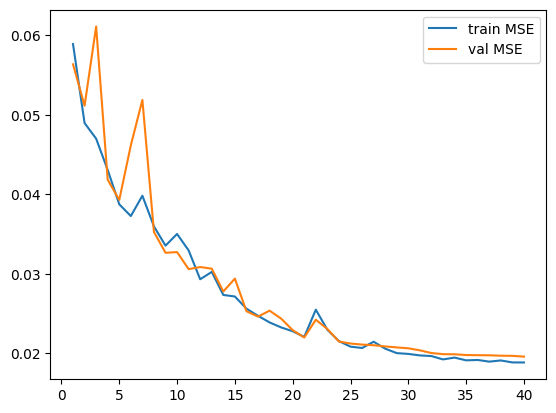

In [8]:
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-5)
scaler = torch.amp.GradScaler("cuda")
start, best, hist = 0, 1e9, []
last = OUT/"ckpt/last.pt"
if last.exists():
    ck = torch.load(last, map_location=device)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    scaler.load_state_dict(ck["scaler"]); start, best, hist = ck["epoch"] + 1, ck["best"], ck["hist"]
    print("Resumed from epoch", start)

for ep in range(start, EPOCHS):
    model.train(); t0 = time.time(); tl = 0
    for _ in range(ITERS):
        x, y = get_batch(tr_n, tr_c, BS, rng_tr)
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16): p = model(x)
        loss = F.mse_loss(p.float(), y)                       # paper: MSE loss
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tl += loss.item()
    sched.step()
    model.eval(); vm = 0
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for k in range(0, len(VX), 512):
            p = model(VX[k:k+512].to(device)).float()
            vm += F.mse_loss(p, VY[k:k+512].to(device), reduction="sum").item()
    vm /= VX.numel(); vpsnr = 10 * np.log10(1 / vm)
    hist.append(dict(epoch=ep + 1, train_mse=tl / ITERS, val_mse=vm, val_psnr=vpsnr))
    if vm < best: best = vm; torch.save({"model": model.state_dict(), "epoch": ep}, OUT/"ckpt/best.pt")
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "scaler": scaler.state_dict(), "epoch": ep, "best": best, "hist": hist}, last)
    print(f"ep {ep+1:02d}/{EPOCHS} | train {tl/ITERS:.5f} | val {vm:.5f} | val PSNR(patch) {vpsnr:.2f} | {time.time()-t0:.0f}s")

h = pd.DataFrame(hist); h.to_csv(OUT/"history.csv", index=False)
plt.plot(h.epoch, h.train_mse, label="train MSE"); plt.plot(h.epoch, h.val_mse, label="val MSE")
plt.legend(); plt.savefig(OUT/"visuals/loss_curve.png", dpi=150); plt.show()

In [9]:
ck = torch.load(OUT/"ckpt/best.pt", map_location=device)
model.load_state_dict(ck["model"]); model.eval(); print("best epoch:", ck["epoch"] + 1)

@torch.no_grad()
def enhance_once(img):
    H, W = img.shape
    Hb, Wb = -(-H // STEP) * STEP, -(-W // STEP) * STEP
    p = np.pad(img, ((40, 40 + Hb - H), (40, 40 + Wb - W)), mode="reflect")
    win = sliding_window_view(p, (PS, PS))[::STEP, ::STEP]
    ny, nx = win.shape[:2]
    flat = np.ascontiguousarray(win.reshape(-1, PS, PS))
    outs = []
    for k in range(0, len(flat), 512):
        t = torch.from_numpy(flat[k:k+512]).float().div(255).unsqueeze(1).to(device)
        with torch.autocast("cuda", dtype=torch.float16): o = model(t)
        outs.append(o[:, 0].float().cpu().numpy())
    outs = np.concatenate(outs).reshape(ny, nx, PS, PS)
    nbi, nbj = Hb // STEP, Wb // STEP
    acc, ws = np.zeros((nbi, nbj, STEP, STEP), np.float32), 0.0
    for di in range(3):
        for dj in range(3):
            w = 1.0 / ((((di - 1) * STEP) ** 2 + ((dj - 1) * STEP) ** 2) + 1.0)   # +1: d=0 par divide-by-zero nahi
            y0, x0 = (2 - di) * STEP, (2 - dj) * STEP
            acc += w * outs[di:di+nbi, dj:dj+nbj, y0:y0+STEP, x0:x0+STEP]; ws += w
    return (acc / ws).transpose(0, 2, 1, 3).reshape(Hb, Wb)[:H, :W]

def enhance(img, n_iter=N_ITER):
    cur = img
    for _ in range(n_iter):
        cur = (enhance_once(cur).clip(0, 1) * 255).round().astype(np.uint8)
    return cur

def metrics(pred, ref):
    rmse = float(np.sqrt(np.mean((pred.astype(np.float64) - ref.astype(np.float64)) ** 2)))
    psnr = 20 * np.log10(255 / rmse) if rmse > 0 else 100.0
    return psnr, rmse, ssim_fn(ref, pred, data_range=255)

best epoch: 40


In [10]:
enhance(cv2.imread(test_df.noisy[0], 0))      # warm-up
rows, times = [], []
for r in tqdm(test_df.itertuples(), total=len(test_df)):
    n = cv2.imread(r.noisy, 0); c = cv2.imread(r.clean, 0)
    assert n.shape == c.shape, r.stem
    torch.cuda.synchronize(); t0 = time.time()
    e = enhance(n)
    torch.cuda.synchronize(); times.append(time.time() - t0)
    dst = OUT/"enhanced_test"/r.rel; dst.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(e).save(dst, dpi=(500, 500))
    pn, rn, sn = metrics(n, c); pe, re_, se = metrics(e, c)
    rows.append(dict(stem=r.stem, rel=r.rel, ftype=r.ftype, noisy=r.noisy, clean=r.clean,
                     noisy_psnr=pn, noisy_rmse=rn, noisy_ssim=sn, enh_psnr=pe, enh_rmse=re_, enh_ssim=se))
res = pd.DataFrame(rows)
print(f"Avg enhancement time: {np.mean(times):.3f} s/image")
res[["noisy_rmse", "enh_rmse", "noisy_psnr", "enh_psnr", "noisy_ssim", "enh_ssim"]].mean()

  0%|          | 0/338 [00:00<?, ?it/s]

Avg enhancement time: 0.877 s/image


noisy_rmse    57.599871
enh_rmse      25.652450
noisy_psnr    13.287521
enh_psnr      20.377271
noisy_ssim     0.671608
enh_ssim       0.901520
dtype: float64

In [11]:
import nbis
from nbis import NbisExtractorSettings

def make_ext(ppi):
    s = NbisExtractorSettings(min_quality=0.0, get_center=False, check_fingerprint=False,
                              compute_nfiq2=True, ppi=ppi)
    return nbis.new_nbis_extractor(s)
try:    ext = make_ext(500)
except Exception as ex:
    print("ppi=500 not accepted, using default:", ex); ext = make_ext(None)

def nfiq2(img):
    ok, buf = cv2.imencode(".png", img)
    try:    return float(ext.extract_minutiae(buf.tobytes()).quality().score)
    except Exception: return np.nan

print([nfiq2(cv2.imread(p, 0)) for p in test_df.clean[:5]])      # sanity check

res["noisy_nfiq2"], res["enh_nfiq2"], res["clean_nfiq2"] = np.nan, np.nan, np.nan
for i, r in tqdm(res.iterrows(), total=len(res)):
    res.at[i, "noisy_nfiq2"] = nfiq2(cv2.imread(r.noisy, 0))
    res.at[i, "enh_nfiq2"]   = nfiq2(cv2.imread(str(OUT/"enhanced_test"/r.rel), 0))
    res.at[i, "clean_nfiq2"] = nfiq2(cv2.imread(r.clean, 0))
res.to_csv(OUT/"test_all_metrics.csv", index=False)
print("NaN counts:", res[["noisy_nfiq2", "enh_nfiq2", "clean_nfiq2"]].isna().sum().to_dict())

[74.0, 65.0, 66.0, 66.0, 73.0]


  0%|          | 0/338 [00:00<?, ?it/s]

NaN counts: {'noisy_nfiq2': 0, 'enh_nfiq2': 0, 'clean_nfiq2': 0}


Test images: 338


,Before (noisy),After (enhanced),Change
SSIM,0.672,0.902,0.230
PSNR (dB),13.288,20.377,7.090
RMSE,57.600,25.652,-31.947
NFIQ2,20.083,70.734,50.651


Clean reference NFIQ2 mean: 71.77
NFIQ2 improved on 336 of 338 images
SSIM improved on 337 of 338 images

Finger type R (n=60)


,Before (noisy),After (enhanced),Change
SSIM,0.558,0.866,0.309
PSNR (dB),11.091,18.272,7.181
RMSE,72.445,32.068,-40.377
NFIQ2,16.350,74.117,57.767



Finger type S (n=93)


,Before (noisy),After (enhanced),Change
SSIM,0.586,0.880,0.294
PSNR (dB),11.906,19.173,7.267
RMSE,66.689,29.082,-37.607
NFIQ2,20.247,74.957,54.710



Finger type U (n=104)


,Before (noisy),After (enhanced),Change
SSIM,0.766,0.925,0.158
PSNR (dB),14.728,21.644,6.916
RMSE,48.003,21.871,-26.133
NFIQ2,18.885,66.856,47.971



Finger type V (n=81)


,Before (noisy),After (enhanced),Change
SSIM,0.732,0.922,0.190
PSNR (dB),14.652,21.694,7.043
RMSE,48.489,21.818,-26.671
NFIQ2,24.198,68.358,44.160


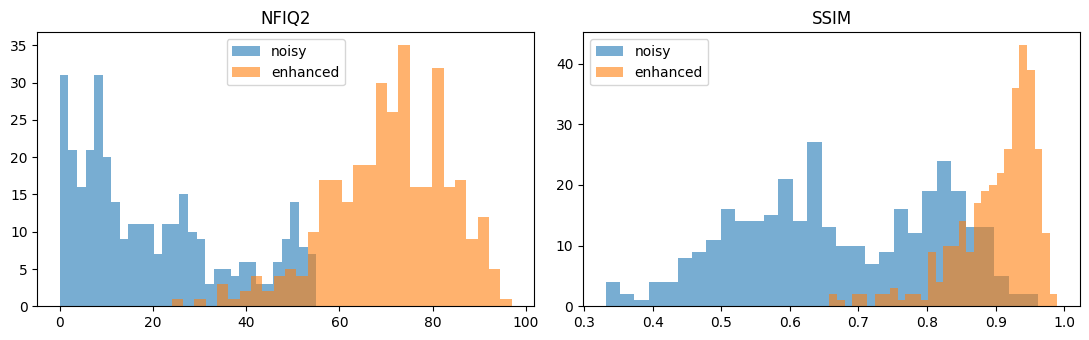

In [12]:
def summ(d):
    t = pd.DataFrame({
        "Before (noisy)":   [d.noisy_ssim.mean(), d.noisy_psnr.mean(), d.noisy_rmse.mean(), d.noisy_nfiq2.mean()],
        "After (enhanced)": [d.enh_ssim.mean(),   d.enh_psnr.mean(),   d.enh_rmse.mean(),   d.enh_nfiq2.mean()]},
        index=["SSIM", "PSNR (dB)", "RMSE", "NFIQ2"])
    t["Change"] = t["After (enhanced)"] - t["Before (noisy)"]
    return t.round(3)

print(f"Test images: {len(res)}"); display(summ(res))
print("Clean reference NFIQ2 mean:", round(res.clean_nfiq2.mean(), 2))
v = res.dropna(subset=["noisy_nfiq2", "enh_nfiq2"])
print(f"NFIQ2 improved on {(v.enh_nfiq2 > v.noisy_nfiq2).sum()} of {len(v)} images")
print(f"SSIM improved on {(res.enh_ssim > res.noisy_ssim).sum()} of {len(res)} images")
for f in sorted(res.ftype.unique()):
    print(f"\nFinger type {f} (n={(res.ftype == f).sum()})"); display(summ(res[res.ftype == f]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(res.noisy_nfiq2.dropna(), 30, alpha=.6, label="noisy")
ax[0].hist(res.enh_nfiq2.dropna(), 30, alpha=.6, label="enhanced"); ax[0].set_title("NFIQ2"); ax[0].legend()
ax[1].hist(res.noisy_ssim, 30, alpha=.6, label="noisy")
ax[1].hist(res.enh_ssim, 30, alpha=.6, label="enhanced"); ax[1].set_title("SSIM"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT/"visuals/hist_nfiq2_ssim.png", dpi=150); plt.show()

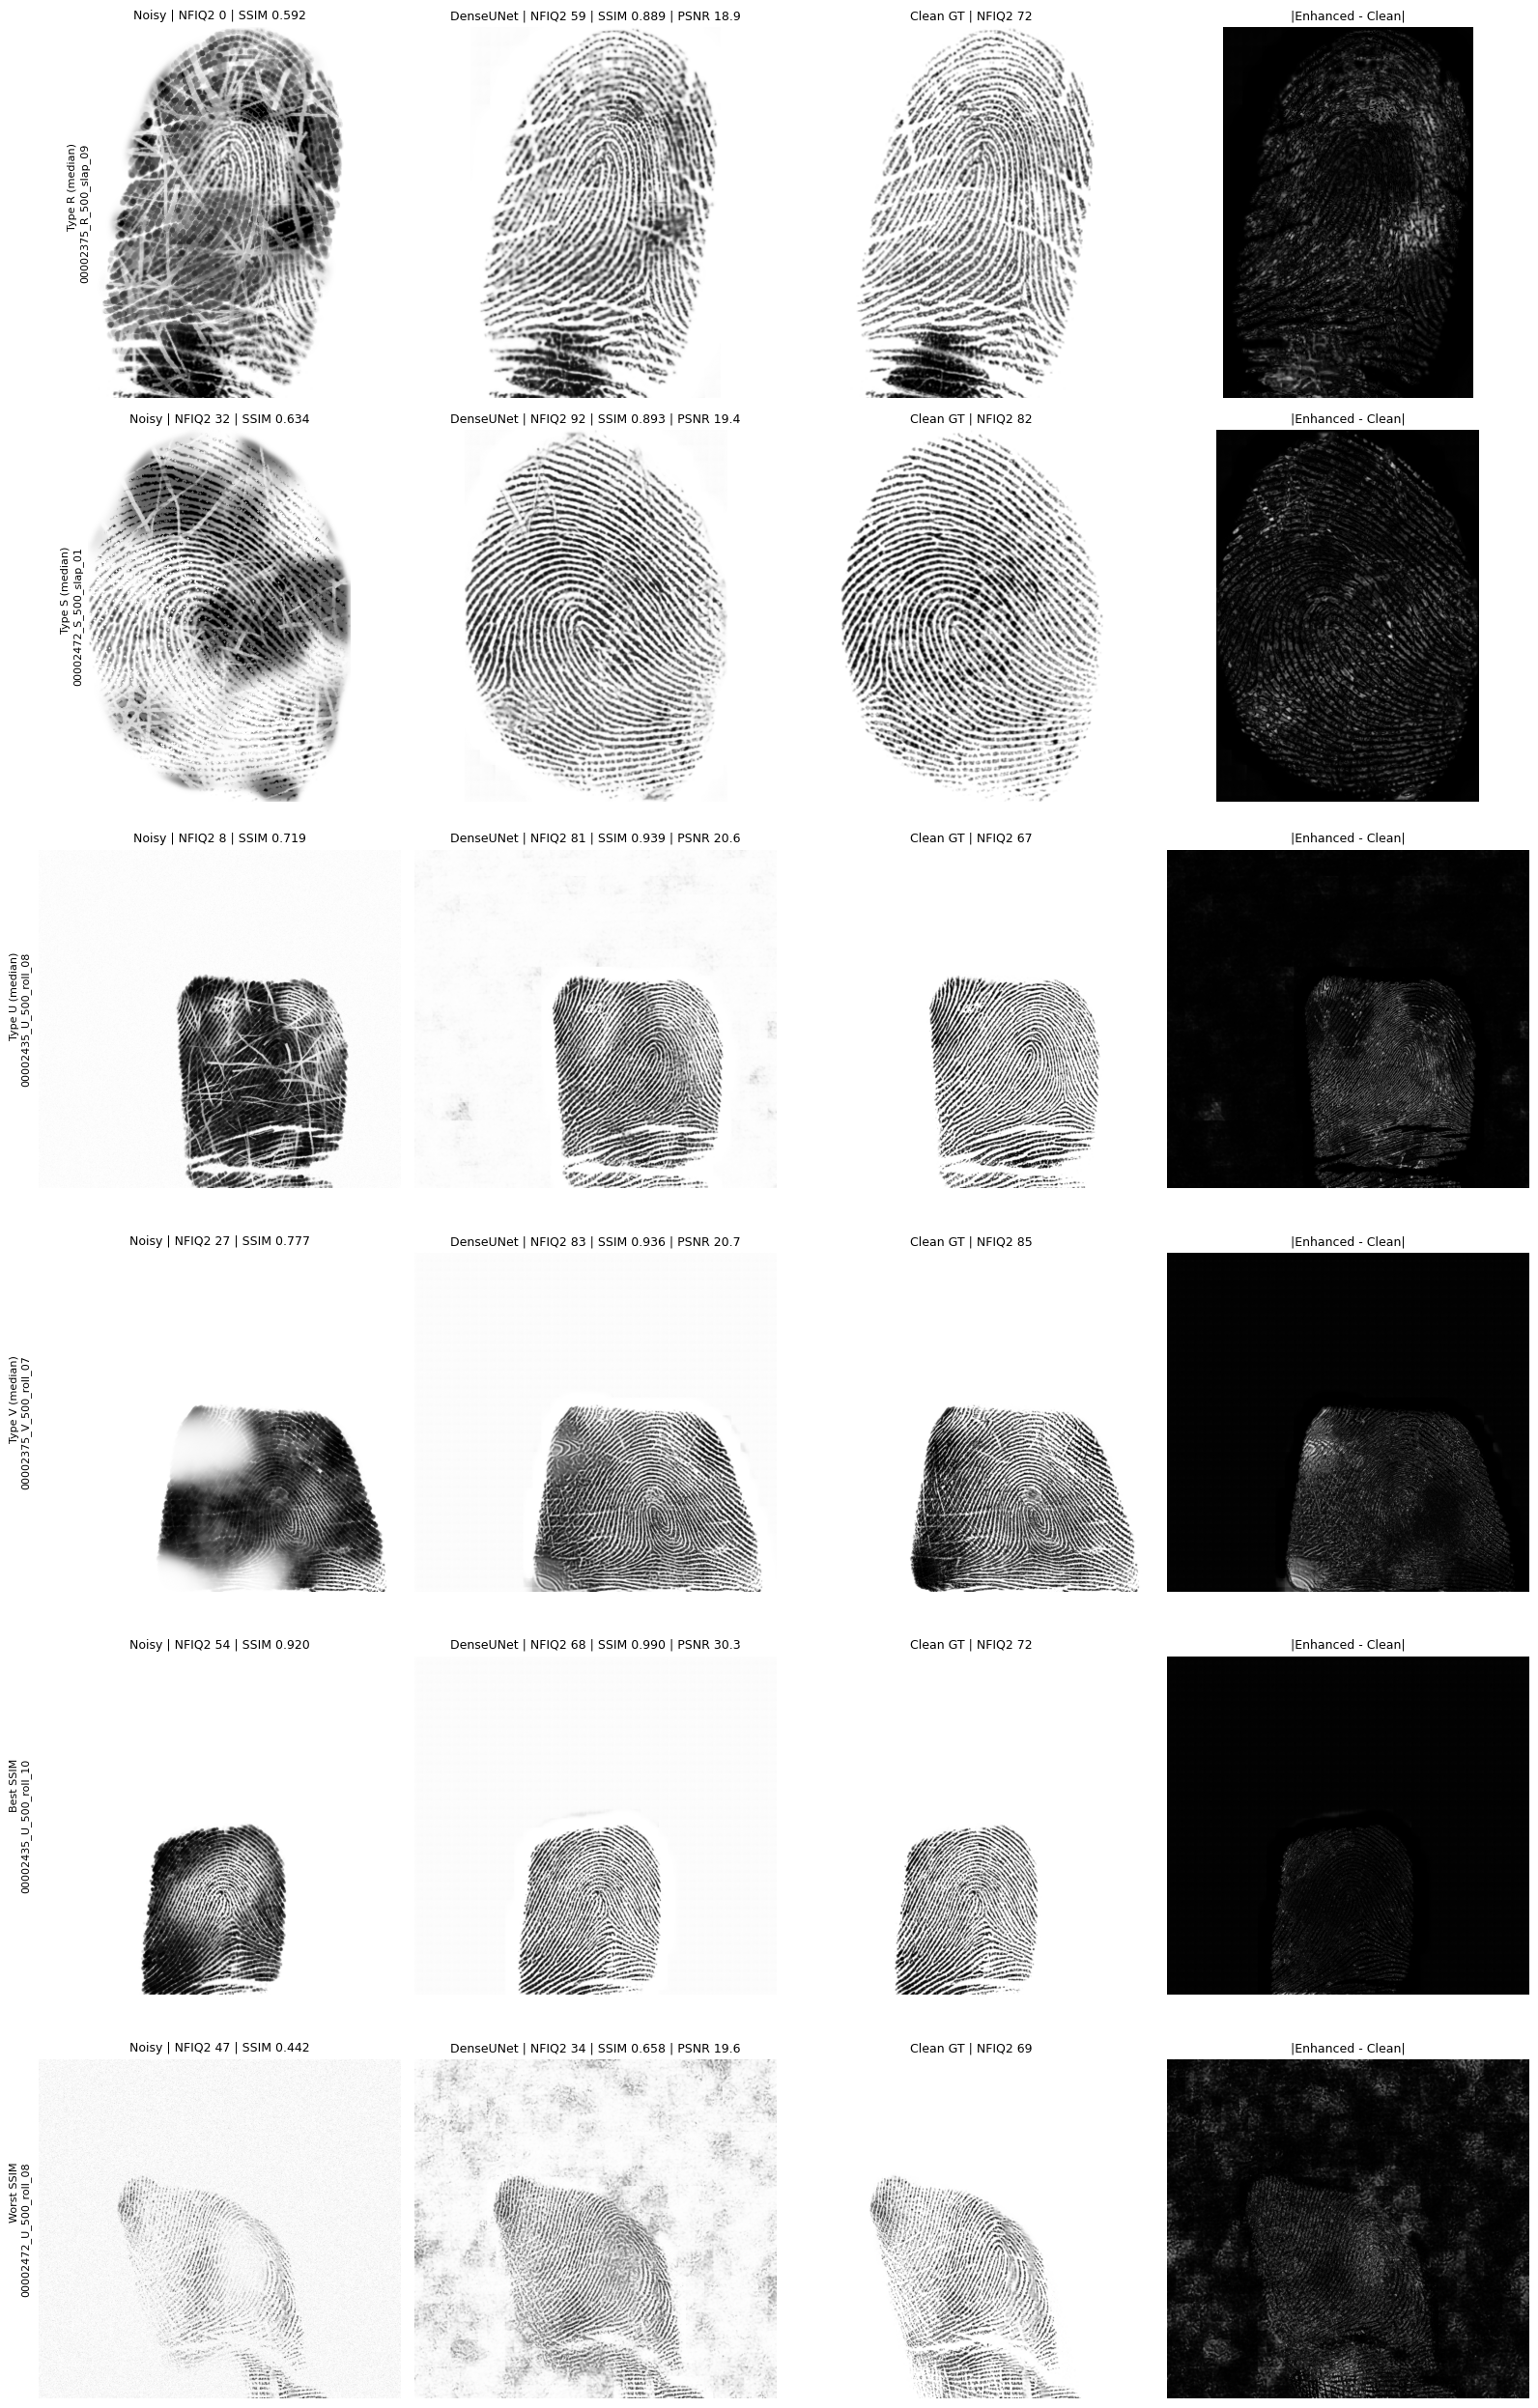

In [13]:
sel = []
for f in sorted(res.ftype.unique()):
    s = res[res.ftype == f].sort_values("enh_ssim")
    if len(s): sel.append((f"Type {f} (median)", s.iloc[len(s) // 2]))
s = res.sort_values("enh_ssim"); sel += [("Best SSIM", s.iloc[-1]), ("Worst SSIM", s.iloc[0])]

fig, axs = plt.subplots(len(sel), 4, figsize=(16, 4.2 * len(sel)))
for i, (tag, r) in enumerate(sel):
    n = cv2.imread(r.noisy, 0); c = cv2.imread(r.clean, 0)
    e = cv2.imread(str(OUT/"enhanced_test"/r.rel), 0)
    diff = np.abs(e.astype(int) - c.astype(int)).astype(np.uint8)
    items = [(n, f"Noisy | NFIQ2 {r.noisy_nfiq2:.0f} | SSIM {r.noisy_ssim:.3f}"),
             (e, f"DenseUNet | NFIQ2 {r.enh_nfiq2:.0f} | SSIM {r.enh_ssim:.3f} | PSNR {r.enh_psnr:.1f}"),
             (c, f"Clean GT | NFIQ2 {r.clean_nfiq2:.0f}"), (diff, "|Enhanced - Clean|")]
    for j, (im, t) in enumerate(items):
        axs[i, j].imshow(im, cmap="gray", vmin=0, vmax=255); axs[i, j].set_title(t, fontsize=9); axs[i, j].axis("off")
    axs[i, 0].text(-0.02, 0.5, f"{tag}\n{r.stem}", transform=axs[i, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"visuals/before_after.png", dpi=130); plt.show()

In [14]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
VIS = OUT/"visuals"; VIS.mkdir(exist_ok=True, parents=True)
METRICS = [("ssim", "SSIM"), ("psnr", "PSNR (dB)"), ("rmse", "RMSE"), ("nfiq2", "NFIQ2")]
C_NOISY, C_ENH, C_CLEAN = "#d95f02", "#1b9e77", "#7570b3"

def save(name):
    plt.tight_layout(); plt.savefig(VIS/f"{name}.png", dpi=200); plt.show()
def ci95(s):
    s = s.dropna(); return 1.96 * s.std(ddof=1) / np.sqrt(len(s))

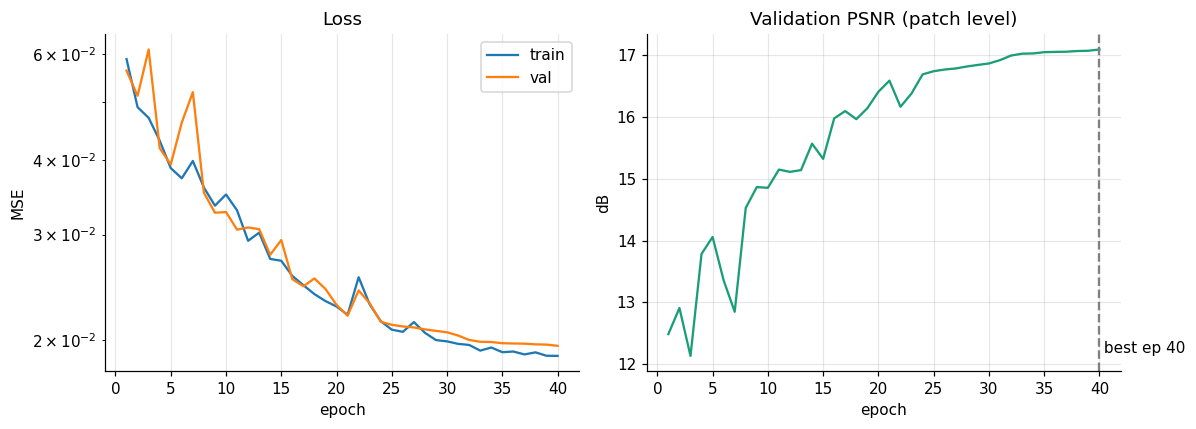

In [15]:
h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h.epoch, h.train_mse, label="train"); ax[0].plot(h.epoch, h.val_mse, label="val")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("MSE"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h.epoch, h.val_psnr, color=C_ENH); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("dB")
ax[1].set_title("Validation PSNR (patch level)")
b = h.val_mse.idxmin(); ax[1].axvline(h.epoch[b], ls="--", c="gray"); ax[1].text(h.epoch[b], h.val_psnr.min(), f" best ep {h.epoch[b]}", va="bottom")
save("g1_training_curves")

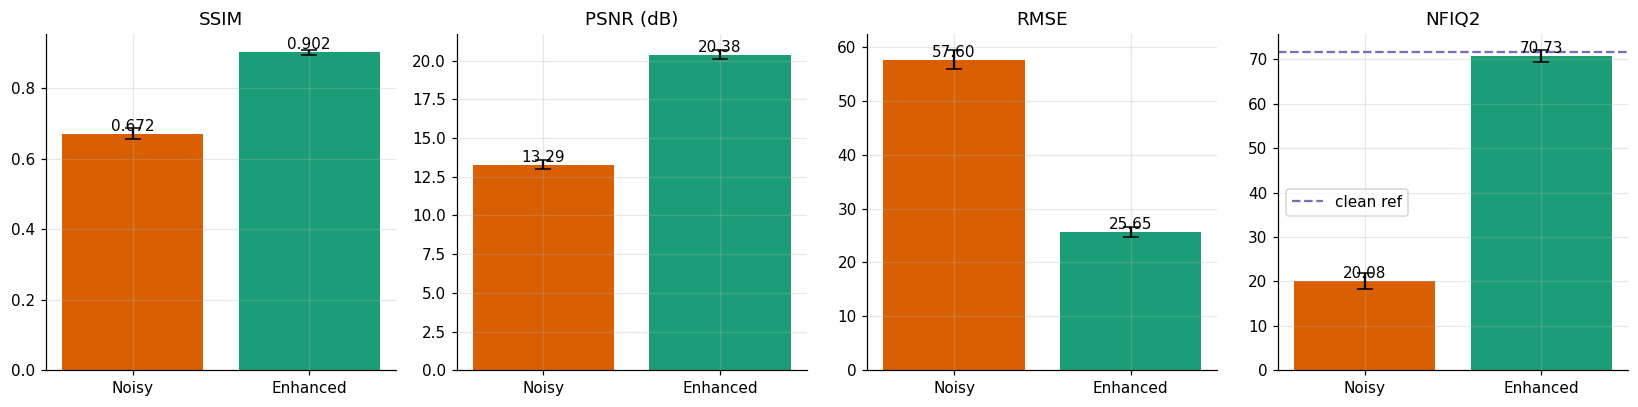

In [16]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for a, (m, t) in zip(ax, METRICS):
    vals = [res[f"noisy_{m}"].mean(), res[f"enh_{m}"].mean()]
    errs = [ci95(res[f"noisy_{m}"]), ci95(res[f"enh_{m}"])]
    a.bar(["Noisy", "Enhanced"], vals, yerr=errs, capsize=5, color=[C_NOISY, C_ENH])
    if m == "nfiq2": a.axhline(res.clean_nfiq2.mean(), ls="--", c=C_CLEAN, label="clean ref"); a.legend()
    for i, v in enumerate(vals): a.text(i, v, f"{v:.3f}" if m == "ssim" else f"{v:.2f}", ha="center", va="bottom")
    a.set_title(t)
save("g2_mean_before_after")

/tmp/ipykernel_49/1421888030.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = a.boxplot(d, labels=["Noisy", "Enhanced"], showmeans=True, patch_artist=True)
/tmp/ipykernel_49/1421888030.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = a.boxplot(d, labels=["Noisy", "Enhanced"], showmeans=True, patch_artist=True)
/tmp/ipykernel_49/1421888030.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = a.boxplot(d, labels=["Noisy", "Enhanced"], showmeans=True, patch_artist=True)
/tmp/ipykernel_49/1421888030.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' s

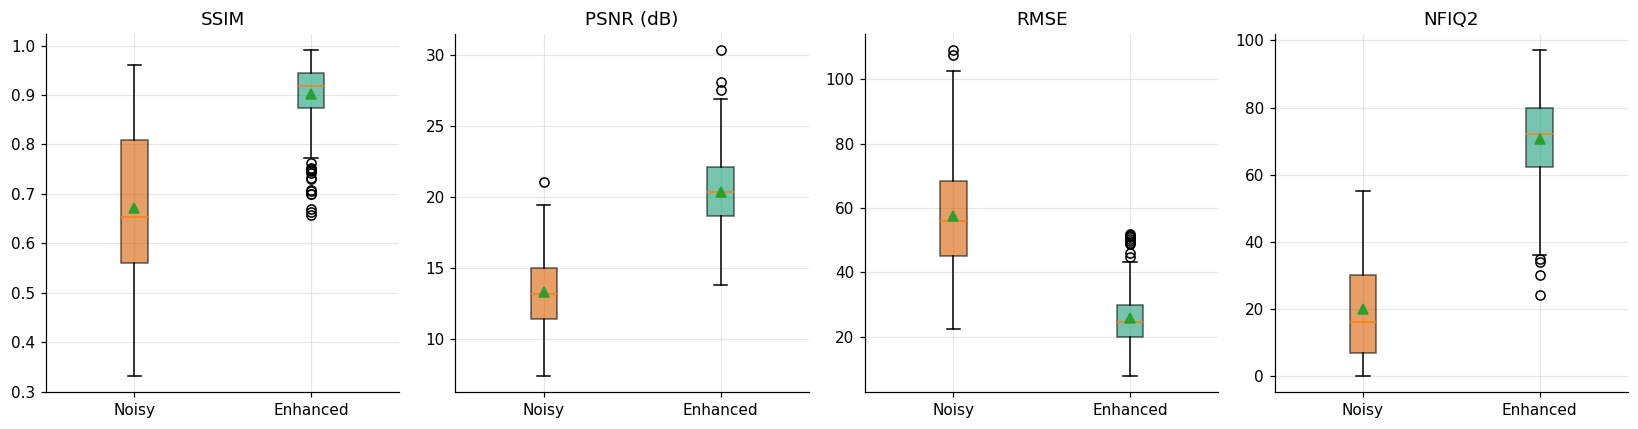

In [17]:
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, (m, t) in zip(ax, METRICS):
    d = [res[f"noisy_{m}"].dropna(), res[f"enh_{m}"].dropna()]
    bp = a.boxplot(d, labels=["Noisy", "Enhanced"], showmeans=True, patch_artist=True)
    for p, c in zip(bp["boxes"], [C_NOISY, C_ENH]): p.set_facecolor(c); p.set_alpha(.6)
    a.set_title(t)
save("g3_boxplots")

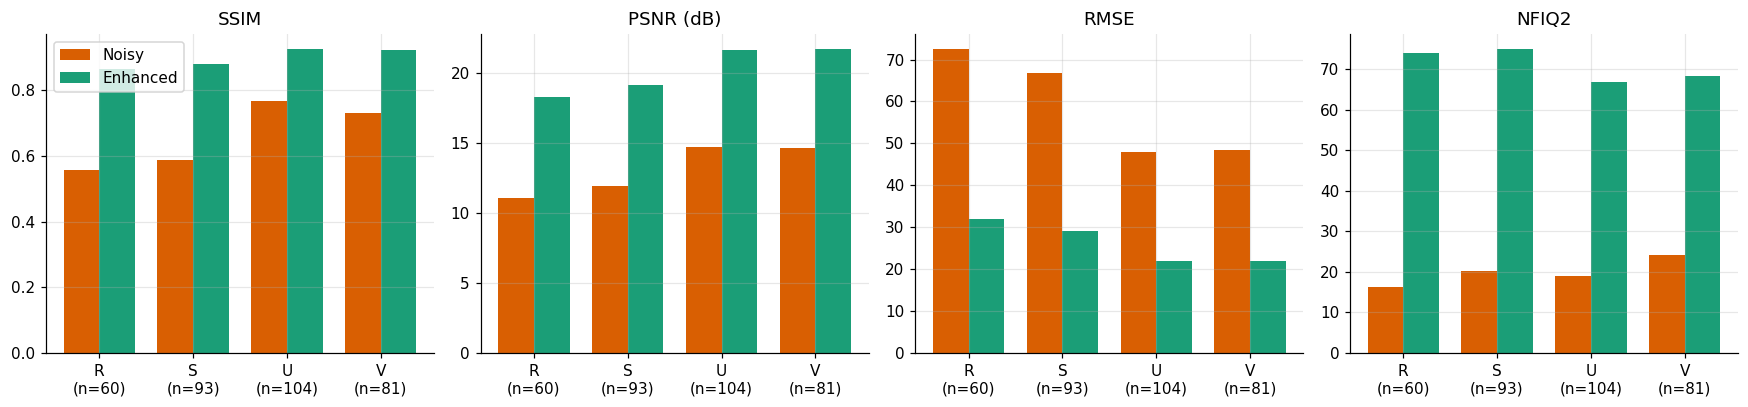

In [18]:
types = sorted(res.ftype.unique()); w = 0.38; x = np.arange(len(types))
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, (m, t) in zip(ax, METRICS):
    nz = [res[res.ftype == f][f"noisy_{m}"].mean() for f in types]
    en = [res[res.ftype == f][f"enh_{m}"].mean() for f in types]
    a.bar(x - w/2, nz, w, label="Noisy", color=C_NOISY); a.bar(x + w/2, en, w, label="Enhanced", color=C_ENH)
    a.set_xticks(x); a.set_xticklabels([f"{f}\n(n={(res.ftype == f).sum()})" for f in types]); a.set_title(t)
ax[0].legend()
save("g4_per_finger_type")

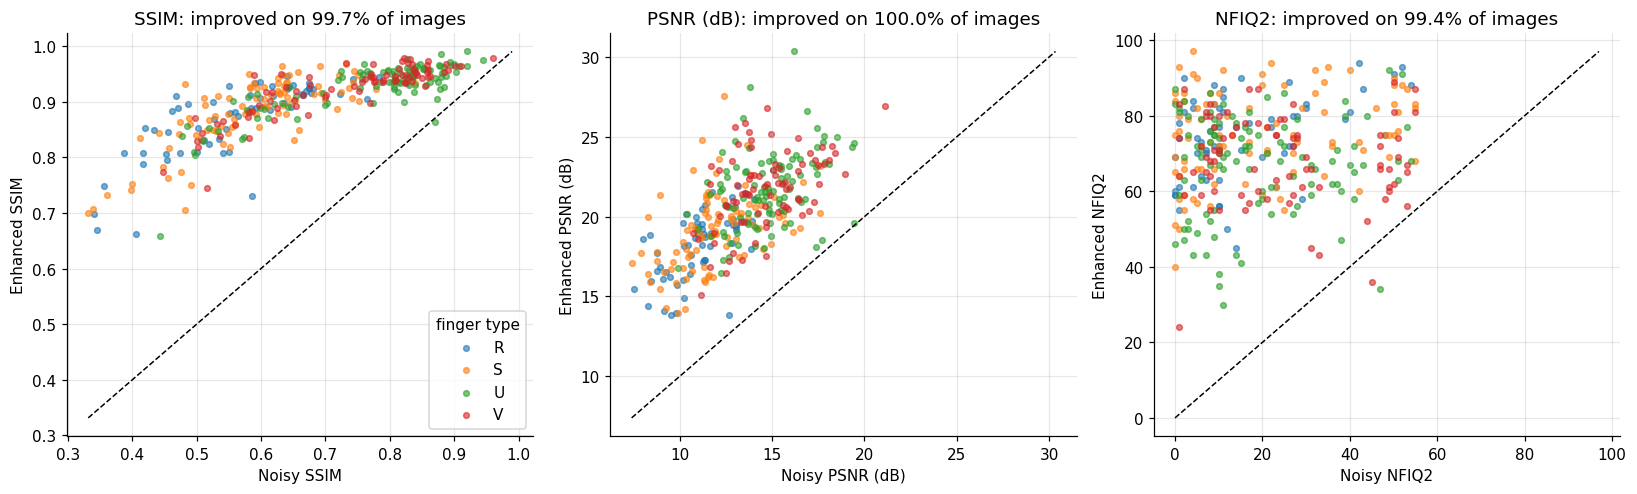

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
cols = dict(zip(types, plt.cm.tab10.colors))
for a, (m, t) in zip(ax, [METRICS[0], METRICS[1], METRICS[3]]):
    d = res.dropna(subset=[f"noisy_{m}", f"enh_{m}"])
    for f in types:
        s = d[d.ftype == f]; a.scatter(s[f"noisy_{m}"], s[f"enh_{m}"], s=14, alpha=.6, color=cols[f], label=f)
    lo = min(d[f"noisy_{m}"].min(), d[f"enh_{m}"].min()); hi = max(d[f"noisy_{m}"].max(), d[f"enh_{m}"].max())
    a.plot([lo, hi], [lo, hi], "k--", lw=1)
    a.set_xlabel(f"Noisy {t}"); a.set_ylabel(f"Enhanced {t}")
    a.set_title(f"{t}: improved on {(d[f'enh_{m}'] > d[f'noisy_{m}']).mean()*100:.1f}% of images")
ax[0].legend(title="finger type")
save("g5_scatter_noisy_vs_enhanced")

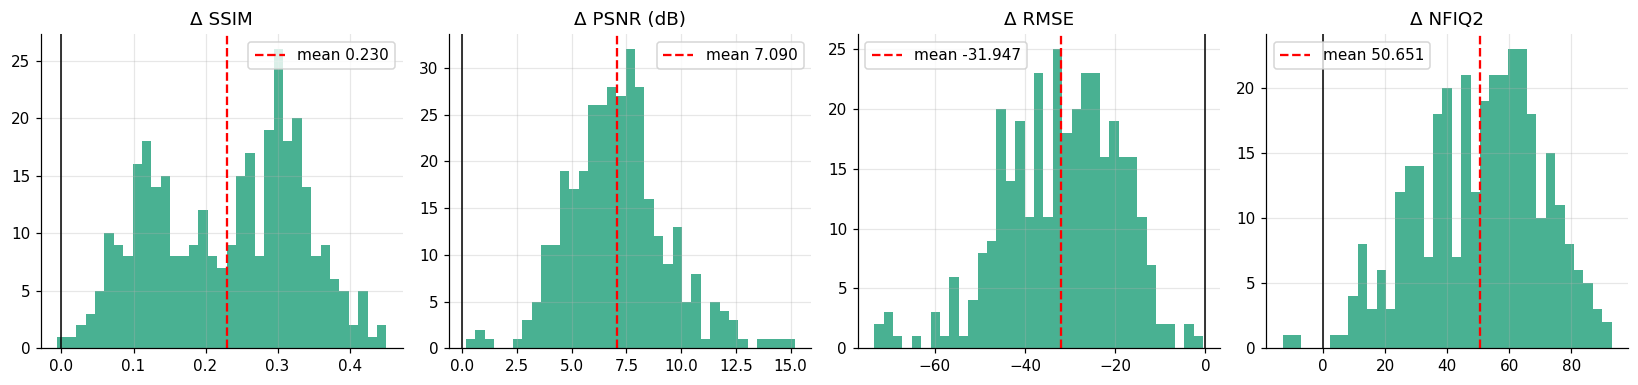

In [20]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, (m, t) in zip(ax, METRICS):
    d = (res[f"enh_{m}"] - res[f"noisy_{m}"]).dropna()
    a.hist(d, 35, color=C_ENH, alpha=.8); a.axvline(0, c="k", lw=1); a.axvline(d.mean(), c="red", ls="--", label=f"mean {d.mean():.3f}")
    a.set_title(f"Δ {t}"); a.legend()
save("g6_delta_histograms")

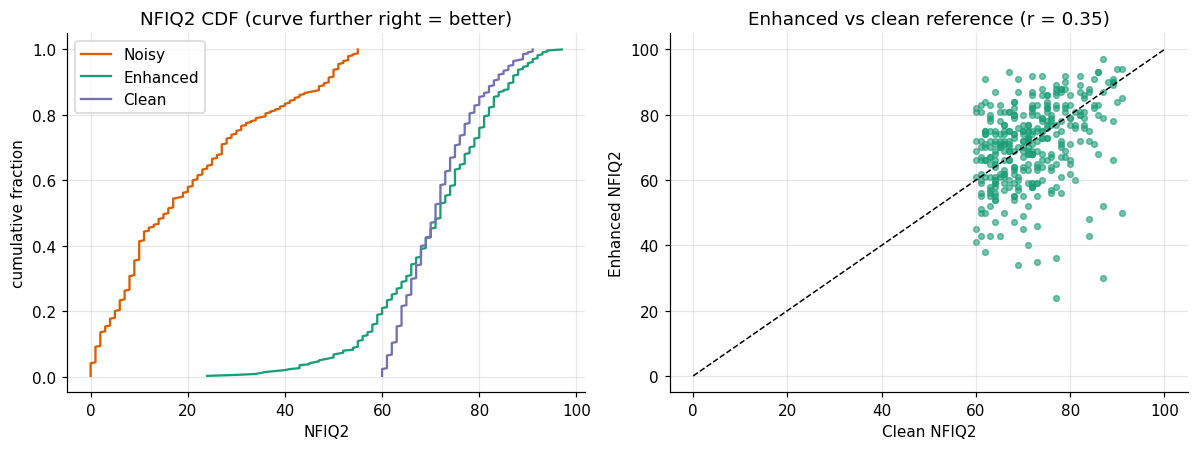

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for col, lab, c in [("noisy_nfiq2", "Noisy", C_NOISY), ("enh_nfiq2", "Enhanced", C_ENH), ("clean_nfiq2", "Clean", C_CLEAN)]:
    s = np.sort(res[col].dropna()); ax[0].plot(s, np.arange(1, len(s)+1)/len(s), label=lab, color=c)
ax[0].set_xlabel("NFIQ2"); ax[0].set_ylabel("cumulative fraction"); ax[0].set_title("NFIQ2 CDF (curve further right = better)"); ax[0].legend()
d = res.dropna(subset=["enh_nfiq2", "clean_nfiq2"])
ax[1].scatter(d.clean_nfiq2, d.enh_nfiq2, s=14, alpha=.6, color=C_ENH); ax[1].plot([0, 100], [0, 100], "k--", lw=1)
ax[1].set_xlabel("Clean NFIQ2"); ax[1].set_ylabel("Enhanced NFIQ2")
ax[1].set_title(f"Enhanced vs clean reference (r = {d.clean_nfiq2.corr(d.enh_nfiq2):.2f})")
save("g7_nfiq2_detail")

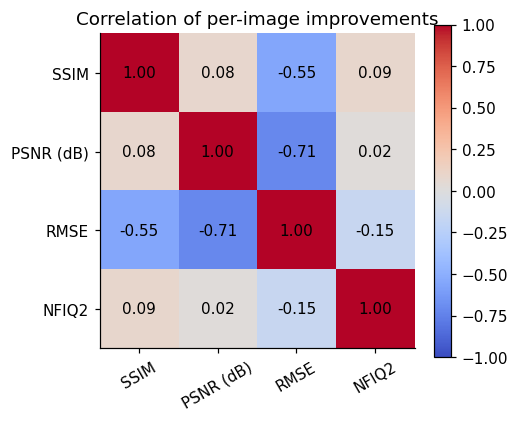

In [22]:
D = pd.DataFrame({t: res[f"enh_{m}"] - res[f"noisy_{m}"] for m, t in METRICS}).dropna()
C = D.corr(); fig, a = plt.subplots(figsize=(4.8, 4))
im = a.imshow(C, cmap="coolwarm", vmin=-1, vmax=1); a.grid(False)
a.set_xticks(range(len(C))); a.set_xticklabels(C.columns, rotation=30); a.set_yticks(range(len(C))); a.set_yticklabels(C.columns)
for i in range(len(C)):
    for j in range(len(C)): a.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im); a.set_title("Correlation of per-image improvements")
save("g8_delta_correlation")

In [23]:
import shutil
from pathlib import Path

SRC = Path("/kaggle/working/denseunet_302b")
ZIP_BASE = "/kaggle/working/denseunet_302b"          # .zip apne aap lag jayega

zip_path = shutil.make_archive(ZIP_BASE, "zip", root_dir=SRC.parent, base_dir=SRC.name)
print("Created:", zip_path, "| size: %.1f MB" % (Path(zip_path).stat().st_size / 1e6))

Created: /kaggle/working/denseunet_302b.zip | size: 63.0 MB
